In [1]:
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem
from openff.toolkit.topology import Molecule
from openff.toolkit.utils.toolkits import OpenEyeToolkitWrapper

from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.molSize = (800, 400)   # Change image size
IPythonConsole.ipython_useSVG = True  # Change output to SVG

from matplotlib import colors
import matplotlib.cm as cm
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG

In [2]:
class MyMolecule():
    def __init__(self, filename):
        
        self.filename = filename
        
        self.ext = filename.split('.')[-1]
        
        if self.ext == 'mol2':
            self.rdkit_mol = Chem.MolFromMol2File(filename, removeHs=False)
        else:
            raise TypeError('File type {} not implemented. File must be a mol2'.format(self.ext))
            
        self.n_atoms = len(self.rdkit_mol.GetAtoms())
        self.charges = np.zeros(self.n_atoms)
        
        self.SMILES = Chem.MolToSmiles(self.rdkit_mol)
        self.molecule = Molecule.from_smiles(self.SMILES)
        self.rdkit_mol = self.molecule.to_rdkit()
        self.names = [a.symbol + str(a.molecule_atom_index) for a in self.molecule.atoms]
    
    
    def write_charges(self, filename):
        
        np.savetxt(filename, self.charges, fmt='%.8f', delimiter=',')
        
        
    def read_charges(self, filename):
        
        charges = np.loadtxt(filename, delimiter=',')
        self.charges = charges
        
        return charges
    

    def assign_charges(self):

        toolkit_registry = OpenEyeToolkitWrapper()
        self.molecule.assign_partial_charges('am1bccelf10', toolkit_registry=toolkit_registry)
        self.charges = self.molecule.partial_charges.magnitude
    
    
    def display(self, show_charges=True, show_index=False, show_names=False, show_colorbar=True, size=(800,400)):
        
        if show_charges:
            for a, atom in enumerate(self.rdkit_mol.GetAtoms()):
                lbl = '%.4f'%(self.charges[a])
                atom.SetProp('atomNote',lbl)

        if show_index:
            for atom in self.rdkit_mol.GetAtoms():
                atom.SetAtomMapNum(atom.GetIdx()+1)
                
        # if show_names:
        #     for a, atom in enumerate(self.rdkit_mol.GetAtoms()):
        #         lbl = f'{self.names[a]}'
        #         atom.SetAtomMapNum(lbl)
        
        # Create a colormap on charges
        cmap = cm.coolwarm
        charge_max = max(self.charges.max(), -self.charges.min())

        norm = colors.Normalize(vmin=-charge_max, vmax=charge_max, clip=True)
        mapper = cm.ScalarMappable(norm=norm, cmap=cmap)

        cs = {}
        atom_set = []
        for i in range(self.n_atoms):
            c = mapper.to_rgba(self.charges[i])
            cs[i] = c
            atom_set.append(i)

        if show_colorbar:
            fig, ax = plt.subplots(1,1, figsize=(10,1))
            ax.axis('off')
            cbar = plt.colorbar(mapper, orientation='horizontal', location='top', fraction=1, label='Charges', ax=ax)

        # draw molecule with atoms colored by charge difference
        drawer = rdMolDraw2D.MolDraw2DSVG(size[0], size[1])
        drawer.drawOptions().useBWAtomPalette()
        drawer.DrawMolecule(self.rdkit_mol, highlightAtoms=atom_set, highlightBonds=[], highlightAtomColors=cs)
        drawer.FinishDrawing()
        svg = drawer.GetDrawingText().replace('svg:','')
        display(SVG(svg))

        return svg
    
    

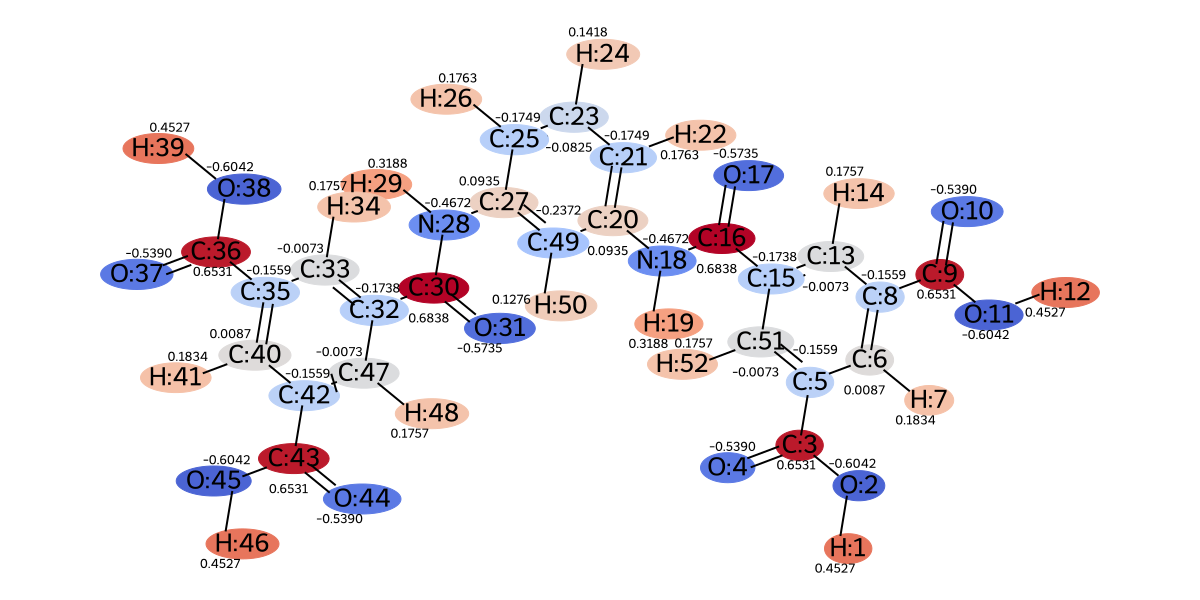

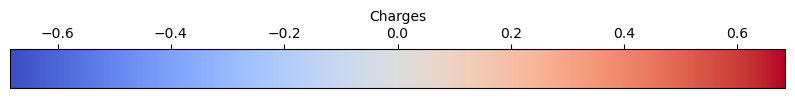

In [3]:
mol = MyMolecule('./1MPD_2TMC_4P/1MPD_2TMC_4P.mol2')
# mol.assign_charges()
# mol.write_charges('./1MPD_2TMC_4P/am1bccelf10.csv')
mol.read_charges('./1MPD_2TMC_4P/am1bccelf10.csv')
svg = mol.display(show_index=True, size=(1200,600))

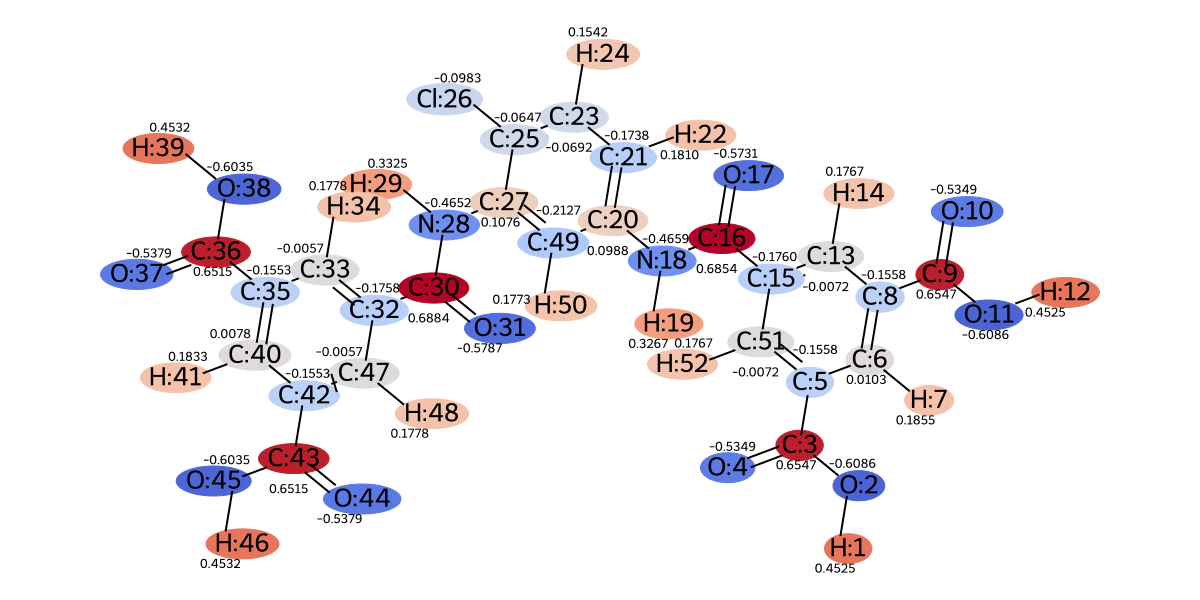

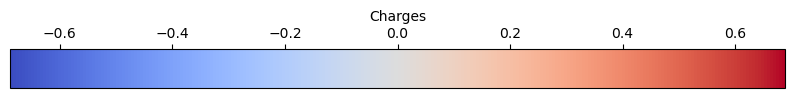

In [7]:
mol1 = MyMolecule('./1MPD_2TMC_4P_Cl/1MPD_2TMC_4P_Cl.mol2')
# mol1.assign_charges()
# mol1.write_charges('./1MPD_2TMC_4P_Cl/am1bccelf10.csv')
mol1.read_charges('./1MPD_2TMC_4P_Cl/am1bccelf10.csv')
svg = mol1.display(show_index=True, size=(1200,600))

In [8]:
mpd = {
    'N1'  : mol.charges[17],
    'hn1' : mol.charges[18],
    'ca3' : mol.charges[19],
    'ca2' : mol.charges[20],
    'ha2' : mol.charges[21],
    'ca1' : mol.charges[22],
    'ha1' : mol.charges[23],
    'ca4' : mol.charges[24],
    'ha4' : mol.charges[25],
    'ca5' : mol.charges[26],
    'N2'  : mol.charges[27],
    'hn2' : mol.charges[28],
    'ca6' : mol.charges[48],
    'ha6' : mol.charges[49]
}

mpd_cl = {
    'N1'  : mol1.charges[27],
    'hn1' : mol1.charges[28],
    'ca3' : mol1.charges[26],
    'ca2' : mol1.charges[24],
    'cl'  : mol1.charges[25],
    'ca1' : mol1.charges[22],
    'ha1' : mol1.charges[23],
    'ca4' : mol1.charges[20],
    'ha4' : mol1.charges[21],
    'ca5' : mol1.charges[19],
    'N2'  : mol1.charges[17],
    'hn2' : mol1.charges[18],
    'ca6' : mol1.charges[48],
    'ha6' : mol1.charges[49]
}

print('Original')
for atom, charge in mpd.items():
    print(f'{atom}\t{charge:.8f}')

print('\nChlorinated')
for atom, charge in mpd_cl.items():
    print(f'{atom}\t{charge:.8f}')

Original
N1	-0.46724001
hn1	0.31883001
ca3	0.09352000
ca2	-0.17495000
ha2	0.17629000
ca1	-0.08255000
ha1	0.14183000
ca4	-0.17495000
ha4	0.17629000
ca5	0.09352000
N2	-0.46724001
hn2	0.31883001
ca6	-0.23725000
ha6	0.12762999

Chlorinated
N1	-0.46518999
hn1	0.33247000
ca3	0.10757000
ca2	-0.06466000
cl	-0.09833000
ca1	-0.06922000
ha1	0.15424000
ca4	-0.17376000
ha4	0.18098000
ca5	0.09883000
N2	-0.46586999
hn2	0.32670000
ca6	-0.21272001
ha6	0.17731001


In [12]:
diffs = []
for atom, charge in mpd_cl.items():
    
    if atom == 'cl':
        charge1 = mpd['ha2']
    else:
        charge1 = mpd[atom]

    if abs(charge - charge1) > 0.01:
        print(f'{atom}\tchanged by\t{charge - charge1:.8f}\tto\t{charge:.8f}')
        diffs.append((charge - charge1))

sum(diffs)

hn1	changed by	0.01363999	to	0.33247000
ca3	changed by	0.01405000	to	0.10757000
ca2	changed by	0.11029000	to	-0.06466000
cl	changed by	-0.27462000	to	-0.09833000
ca1	changed by	0.01333000	to	-0.06922000
ha1	changed by	0.01241000	to	0.15424000
ca6	changed by	0.02452999	to	-0.21272001
ha6	changed by	0.04968002	to	0.17731001


-0.036689995125738534

In [10]:
for atom, charge in mpd_cl.items():
    
    if atom == 'cl':
        charge1 = mpd['ha2']
    else:
        charge1 = mpd[atom]

    if not abs(charge - charge1) > 0.01:
        print(f'{atom}\tunchanged at\t{charge:.8f}')

N1	unchanged at	-0.46518999
ca4	unchanged at	-0.17376000
ha4	unchanged at	0.18098000
ca5	unchanged at	0.09883000
N2	unchanged at	-0.46586999
hn2	unchanged at	0.32670000
